# $D$ vs. total active terms

This notebook compares QITE and sparse (LASSO) QITE in the ordered and disordered phases. For each run, the **total active terms** is defined as

$$K_{\mathrm{total}} = \sum_t K_t,$$

where `K_t` is the number of active terms at evolution step $t$ in `support_metrics.csv`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 120, "font.size": 11})

In [2]:
# The notebook is intended to live beside manifest.csv. This fallback also
# works when a Jupyter kernel starts from the repository root.
candidates = [Path.cwd(), Path.cwd() / "Rafa files"]
BASE_DIR = next((p for p in candidates if (p / "manifest.csv").exists()), None)
if BASE_DIR is None:
    raise FileNotFoundError("Could not find manifest.csv in the working directory or ./Rafa files")

manifest = pd.read_csv(BASE_DIR / "manifest.csv")
manifest[["phase", "D", "best_lambda"]]

,phase,D,best_lambda
0,ordered,2,0.0700
1,ordered,3,0.0200
2,ordered,4,0.0007
3,ordered,5,0.0070
4,ordered,6,0.0050
5,ordered,7,0.0300
6,disordered,2,0.0700
7,disordered,3,0.0700
8,disordered,4,0.0700
9,disordered,5,0.0700


In [3]:
def local_run_dir(row, method):
    """Resolve a copied run directory from a manifest row."""
    source_column = f"{method}_dst"
    run_name = Path(row[source_column]).name
    return BASE_DIR / row["phase"] / method / run_name


records = []
for _, row in manifest.iterrows():
    for method, label in [("qite", "QITE"), ("sparse_qite", "LASSO-QITE")]:
        csv_path = local_run_dir(row, method) / "support_metrics.csv"
        metrics = pd.read_csv(csv_path)
        if "K_t" not in metrics:
            raise KeyError(f"K_t is missing from {csv_path}")
        records.append({
            "phase": row["phase"],
            "D": int(row["D"]),
            "method": label,
            "total_active_terms": int(metrics["K_t"].sum()),
            "n_steps": len(metrics),
            "lambda": None if method == "qite" else row["best_lambda"],
        })

totals = pd.DataFrame(records).sort_values(["phase", "method", "D"]).reset_index(drop=True)
totals

,phase,D,method,total_active_terms,n_steps,lambda
0,disordered,2,LASSO-QITE,840,100,0.0700
1,disordered,3,LASSO-QITE,3079,100,0.0700
2,disordered,4,LASSO-QITE,6248,100,0.0700
3,disordered,5,LASSO-QITE,8443,100,0.0700
4,disordered,6,LASSO-QITE,10087,100,0.1000
5,disordered,7,LASSO-QITE,13417,100,0.1000
6,disordered,2,QITE,4800,100,NaN
7,disordered,3,QITE,22384,100,NaN
8,disordered,4,QITE,95832,100,NaN
9,disordered,5,QITE,395956,100,NaN


In [4]:
# Fit the disordered LASSO-QITE data in log space.
fit_data = totals.query("phase == 'disordered' and method == 'LASSO-QITE'").sort_values("D")
D_fit = fit_data["D"].to_numpy(dtype=float)
K_fit = fit_data["total_active_terms"].to_numpy(dtype=float)

power_slope, power_intercept = np.polyfit(np.log(D_fit), np.log(K_fit), 1)
exp_slope, exp_intercept = np.polyfit(D_fit, np.log(K_fit), 1)
power_prefactor = np.exp(power_intercept)
exp_prefactor = np.exp(exp_intercept)
power_prediction = power_prefactor * D_fit**power_slope
exp_prediction = exp_prefactor * np.exp(exp_slope * D_fit)

def log_r_squared(observed, predicted):
    residual = np.sum((np.log(observed) - np.log(predicted))**2)
    total = np.sum((np.log(observed) - np.log(observed).mean())**2)
    return 1 - residual / total

power_r2 = log_r_squared(K_fit, power_prediction)
exp_r2 = log_r_squared(K_fit, exp_prediction)
print(f"Power law:  K_total = {power_prefactor:.1f} D^{power_slope:.2f}  (log-space R² = {power_r2:.3f})")
print(f"Exponential: K_total = {exp_prefactor:.1f} exp({exp_slope:.3f} D)  (log-space R² = {exp_r2:.3f})")


Power law:  K_total = 244.0 D^2.15  (log-space R² = 0.958)
Exponential: K_total = 527.1 exp(0.506 D)  (log-space R² = 0.862)


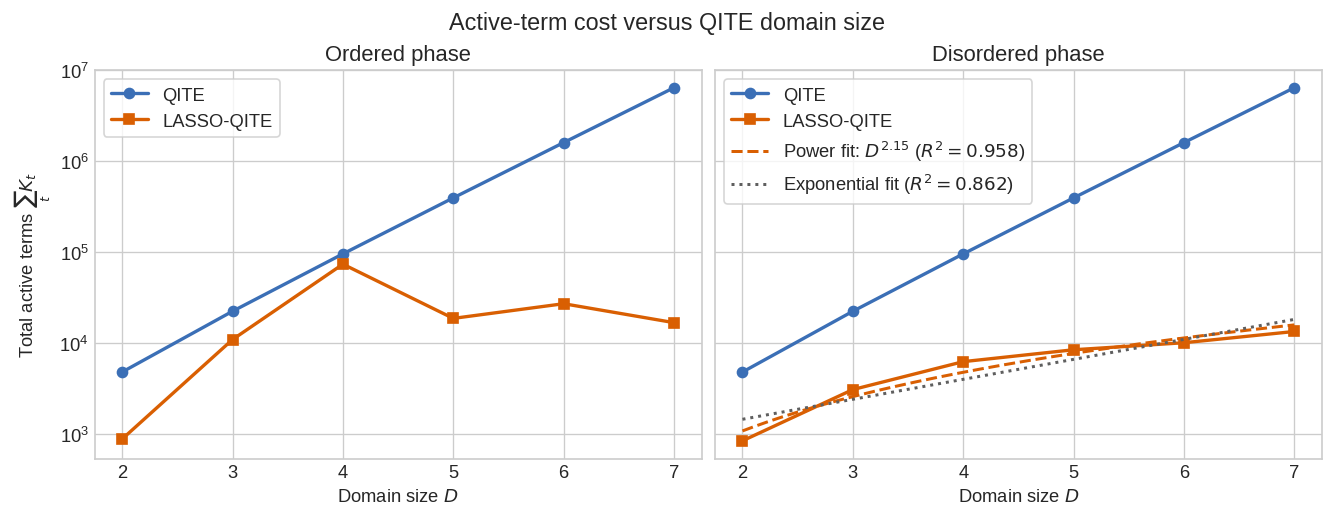

In [5]:
colors = {"QITE": "#3b6fb6", "LASSO-QITE": "#d95f02"}
markers = {"QITE": "o", "LASSO-QITE": "s"}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True, constrained_layout=True)
for ax, phase in zip(axes, ["ordered", "disordered"]):
    phase_data = totals[totals["phase"] == phase]
    for method in ["QITE", "LASSO-QITE"]:
        data = phase_data[phase_data["method"] == method]
        ax.plot(
            data["D"], data["total_active_terms"],
            label=method, color=colors[method], marker=markers[method],
            linewidth=2, markersize=6,
        )
    if phase == "disordered":
        D_smooth = np.linspace(D_fit.min(), D_fit.max(), 300)
        ax.plot(
            D_smooth, power_prefactor * D_smooth**power_slope,
            color=colors["LASSO-QITE"], linestyle="--", linewidth=1.8,
            label=rf"Power fit: $D^{{{power_slope:.2f}}}$ ($R^2={power_r2:.3f}$)",
        )
        ax.plot(
            D_smooth, exp_prefactor * np.exp(exp_slope * D_smooth),
            color="#5f5f5f", linestyle=":", linewidth=1.8,
            label=rf"Exponential fit ($R^2={exp_r2:.3f}$)",
        )
    ax.set(title=f"{phase.capitalize()} phase", xlabel="Domain size $D$", yscale="log")
    ax.set_xticks(sorted(phase_data["D"].unique()))
    ax.legend(frameon=True)

axes[0].set_ylabel(r"Total active terms $\sum_t K_t$")
fig.suptitle("Active-term cost versus QITE domain size", fontsize=14)
plt.show()

,D,total_active_terms,total_active_terms_over_D2
0,2,840,210.000000
1,3,3079,342.111111
2,4,6248,390.500000
3,5,8443,337.720000
4,6,10087,280.194444
5,7,13417,273.816327


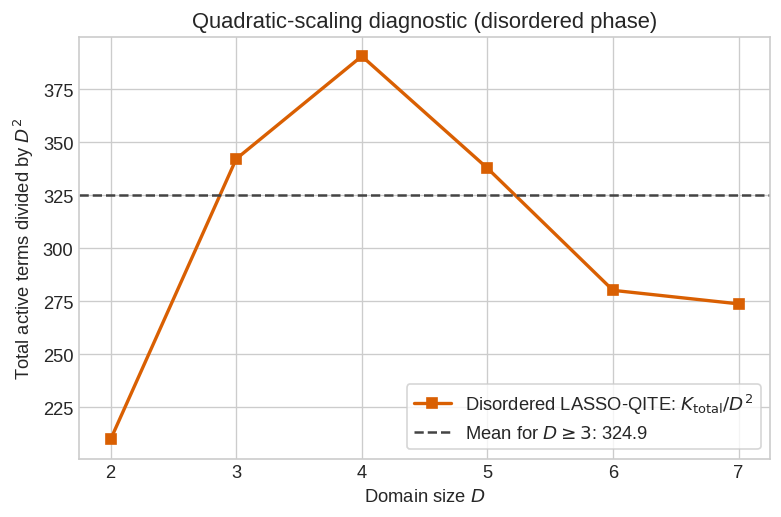

Mean K_total/D² (all D): 305.7
Mean K_total/D² (D >= 3): 324.9
Relative range for D >= 3: 0.84 to 1.20 times the mean


In [6]:
# Quadratic-scaling diagnostic for disordered LASSO-QITE.
quadratic_check = fit_data[["D", "total_active_terms"]].copy()
quadratic_check["total_active_terms_over_D2"] = (
    quadratic_check["total_active_terms"] / quadratic_check["D"]**2
)
display(quadratic_check)

# D=2 can have a stronger finite-size effect, so show both full and D >= 3 means.
ratio_mean_all = quadratic_check["total_active_terms_over_D2"].mean()
ratio_mean_D3 = quadratic_check.loc[
    quadratic_check["D"] >= 3, "total_active_terms_over_D2"
].mean()

fig, ax = plt.subplots(figsize=(6.4, 4.2), constrained_layout=True)
ax.plot(
    quadratic_check["D"], quadratic_check["total_active_terms_over_D2"],
    color=colors["LASSO-QITE"], marker="s", linewidth=2, markersize=6,
    label=r"Disordered LASSO-QITE: $K_{\rm total}/D^2$",
)
ax.axhline(
    ratio_mean_D3, color="#444444", linestyle="--", linewidth=1.5,
    label=rf"Mean for $D\geq3$: {ratio_mean_D3:.1f}",
)
ax.set(
    title="Quadratic-scaling diagnostic (disordered phase)",
    xlabel="Domain size $D$",
    ylabel=r"Total active terms divided by $D^2$",
)
ax.set_xticks(D_fit.astype(int))
ax.legend(frameon=True)
plt.show()

print(f"Mean K_total/D² (all D): {ratio_mean_all:.1f}")
print(f"Mean K_total/D² (D >= 3): {ratio_mean_D3:.1f}")
print(
    "Relative range for D >= 3: "
    f"{quadratic_check.loc[quadratic_check.D >= 3, 'total_active_terms_over_D2'].min() / ratio_mean_D3:.2f}"
    " to "
    f"{quadratic_check.loc[quadratic_check.D >= 3, 'total_active_terms_over_D2'].max() / ratio_mean_D3:.2f}"
    " times the mean"
)


The vertical axis is cumulative across the full run. If runs with different numbers of steps are compared later, `total_active_terms / n_steps` gives the mean active terms per step.